# pandas 2.x & 3.0 (Copy-on-Write, Arrow Types)

pandas changed a lot between versions 1.5 (2022) and 3.0 (2026). Two changes affect almost every program: **Copy-on-Write** (CoW), which makes copying behaviour predictable, and **Apache Arrow** types, which make text, missing values and data exchange faster and more consistent. Old tutorials and Stack Overflow answers often show patterns that no longer work.

**After this lesson you can:**

1. Explain Copy-on-Write and why chained assignment no longer works.
2. Use the new `str` dtype and Arrow-backed types (`int64[pyarrow]`, `timestamp[us][pyarrow]`).
3. Handle missing values with the nullable dtypes (`pd.NA`).
4. Exchange data with other tools without copying (Arrow, Polars, DuckDB).
5. Migrate old pandas code: a checklist.

**Data:** NYC yellow taxi trips, January 2024, and Palmer penguins.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

import pyarrow as pa

print("pandas", pd.__version__, "| pyarrow", pa.__version__)
trips = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"])
penguins = pd.read_json(datasets.fetch("penguins.json"))

pandas 3.1.1 | pyarrow 26.0.1


## 1. A Short History

| Version | Year | Main changes |
| :--- | :--- | :--- |
| 1.0 | 2020 | nullable `Int64`, `string` and `boolean` dtypes (opt-in), `pd.NA` |
| 2.0 | 2023 | optional Arrow-backed dtypes (`dtype_backend="pyarrow"`), non-nanosecond datetimes, CoW opt-in |
| 2.2 | 2024 | warnings for patterns that 3.0 changes |
| 3.0 | 2026 | **CoW always on**, **`str` dtype by default** (Arrow-backed), removal of deprecated APIs |

## 2. Copy-on-Write

Before CoW, a selection was sometimes a **view** and sometimes a **copy**, depending on internal details. Modifying it could change the original or not, and pandas warned with the infamous `SettingWithCopyWarning`. With CoW:

- every DataFrame or Series derived from another one **behaves like a copy**;
- pandas still shares the memory until one of them is modified (copy **on write**), so selections stay cheap.

In [2]:
df = trips.head(5)[["fare_amount", "tip_amount"]]
col = df["fare_amount"]                       # shares memory with df for now
print("shares memory before the write:", np.shares_memory(col.to_numpy(), df["fare_amount"].to_numpy()))
col.iloc[0] = 999.0                           # writing triggers the copy
print("df unchanged:", df["fare_amount"].iloc[0], "| col changed:", col.iloc[0])

import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    df[df["fare_amount"] > 10]["tip_amount"] = 0  # chained assignment: has NO effect under CoW
print("pandas warned:", type(caught[0].message).__name__ if caught else "no warning")
print("chained assignment changed nothing:", (df["tip_amount"] == 0).sum() == (trips.head(5)["tip_amount"] == 0).sum())
df.loc[df["fare_amount"] > 10, "tip_amount"] = 0   # the correct form
print("after .loc:", df["tip_amount"].tolist())

shares memory before the write: True
df unchanged: 17.7 | col changed: 999.0
pandas warned: ChainedAssignmentError
chained assignment changed nothing: True
after .loc: [0.0, 3.75, 0.0, 2.0, 3.2]


CoW also makes many operations faster, because methods such as `rename`, `reset_index`, `set_axis` or `drop` (of columns) no longer copy the data immediately.

In [3]:
big = trips.copy()
t = time.perf_counter()
for _ in range(50):
    out = big.rename(columns={"fare_amount": "fare"}).reset_index(drop=True)
per_call = (time.perf_counter() - t) / 50 * 1000
print(f"rename + reset_index on {len(big):,} rows: {per_call:.2f} ms per call (no data copied)")
print("result shares memory with the input:", np.shares_memory(out["fare"].to_numpy(), big["fare_amount"].to_numpy()))

rename + reset_index on 2,964,624 rows: 1.07 ms per call (no data copied)
result shares memory with the input: True


## 3. Text: the `str` dtype

pandas 3 stores text in the `str` dtype, backed by PyArrow when it is installed. It uses much less memory than Python objects, and string methods run in compiled code.

In [4]:
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
names = trips["PULocationID"].map(zones.set_index("LocationID")["Zone"]).dropna()
as_object = names.astype(object)
print("dtype:", names.dtype, "| object version:", as_object.dtype)
mem = {"str (default)": names.memory_usage(deep=True) / 1e6, "object": as_object.memory_usage(deep=True) / 1e6}
speed = {}
for label, s in [("str (default)", names), ("object", as_object)]:
    t = time.perf_counter(); s.str.contains("Airport"); speed[label] = (time.perf_counter() - t) * 1000
print({k: f"{v:.0f} MB" for k, v in mem.items()}, {k: f"{v:.0f} ms for .str.contains" for k, v in speed.items()})

dtype: str | object version: object


{'str (default)': '96 MB', 'object': '217 MB'} {'str (default)': '321 ms for .str.contains', 'object': '580 ms for .str.contains'}


## 4. Missing Values and Nullable Types

NumPy integers cannot hold missing values, so classic pandas converted an integer column with one missing value to `float64`. The **nullable** dtypes (`Int64`, `boolean`, `string`) and the **Arrow** dtypes keep integers as integers and use `pd.NA` for missing values.

In [5]:
pc = trips["passenger_count"]                                  # float64 because of the missing values
print("numpy-backed:", pc.dtype, "| example values:", pc.head(3).tolist())
nullable = pc.astype("Int64")
arrow = pc.astype("int64[pyarrow]")
print("nullable    :", nullable.dtype, "| missing:", nullable.isna().sum(), "| value of a missing cell:", nullable[nullable.isna()].iloc[0])
print("arrow       :", arrow.dtype, "| memory MB:", round(arrow.memory_usage(deep=True) / 1e6, 1), "vs float64",
      round(pc.memory_usage(deep=True) / 1e6, 1))

arrow_df = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "passenger_count", "fare_amount"],
                           dtype_backend="pyarrow")
print("\nread with dtype_backend='pyarrow':")
print(arrow_df.dtypes)

numpy-backed: float64 | example values: [1.0, 1.0, 1.0]
nullable    : Int64 | missing: 140162 | value of a missing cell: <NA>
arrow       : int64[pyarrow] | memory MB: 24.1 vs float64 23.7



read with dtype_backend='pyarrow':
tpep_pickup_datetime    timestamp[us][pyarrow]
passenger_count                 int64[pyarrow]
fare_amount                    double[pyarrow]
dtype: object


Logic with `pd.NA` follows **three-valued logic**: `NA & False` is `False`, `NA | True` is `True`, and comparisons with `NA` give `NA`. Filters treat `NA` as "not selected".

## 5. Zero-Copy Exchange with Arrow

Apache Arrow is a standard **in-memory** columnar format. pandas (with Arrow dtypes), Polars, DuckDB, PyArrow and Spark can pass Arrow data to each other with little or no conversion. The timings below show the remaining cost on 3 million rows: it is far below the cost of serialising to CSV or Parquet and reading back, but it is not zero (some steps still combine chunks or convert types).

In [6]:
import duckdb
import polars as pl

timings = {}
t = time.perf_counter(); arrow_table = pa.Table.from_pandas(arrow_df); timings["pandas (arrow) -> pyarrow"] = time.perf_counter() - t
t = time.perf_counter(); pl_df = pl.from_arrow(arrow_table); timings["pyarrow -> polars"] = time.perf_counter() - t
t = time.perf_counter(); res = duckdb.sql("SELECT avg(fare_amount) AS avg_fare FROM arrow_table").fetchall(); timings["duckdb query on arrow"] = time.perf_counter() - t
t = time.perf_counter(); back = pl_df.to_pandas(use_pyarrow_extension_array=True); timings["polars -> pandas (arrow)"] = time.perf_counter() - t
print({k: f"{v * 1000:.1f} ms" for k, v in timings.items()}, "| avg fare:", round(res[0][0], 2))

{'pandas (arrow) -> pyarrow': '15.7 ms', 'pyarrow -> polars': '522.4 ms', 'duckdb query on arrow': '96.4 ms', 'polars -> pandas (arrow)': '71.6 ms'} | avg fare: 18.18


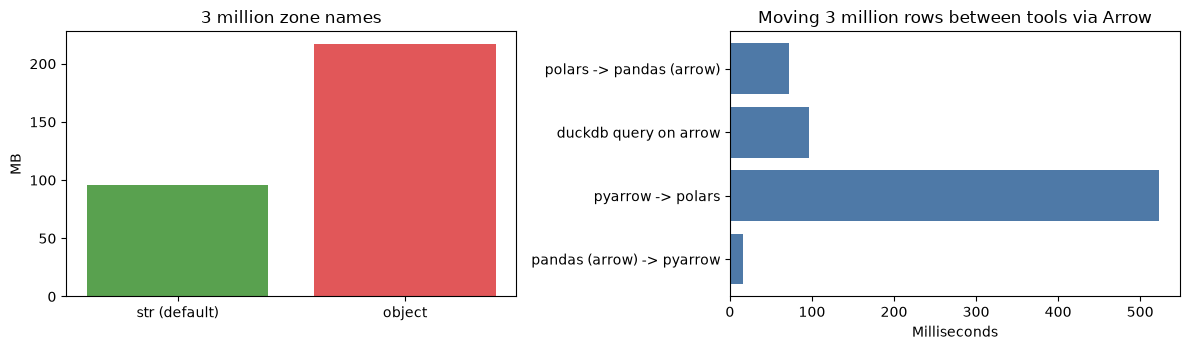

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.bar(mem.keys(), mem.values(), color=["#59A14F", "#E15759"])
ax1.set(title="3 million zone names", ylabel="MB")
ax2.barh(list(timings), [v * 1000 for v in timings.values()], color="#4E79A7")
ax2.set(title="Moving 3 million rows between tools via Arrow", xlabel="Milliseconds")
plt.tight_layout()
plt.show()

## 6. Migration Checklist

| Old pattern | Problem in pandas 3 | New pattern |
| :--- | :--- | :--- |
| `df[mask]["col"] = v` | does nothing | `df.loc[mask, "col"] = v` |
| `df["col"][0] = v` | does nothing | `df.loc[0, "col"] = v` |
| `inplace=True` everywhere | no speed benefit, blocks chaining | assign the result: `df = df.dropna()` |
| `dtype == object` checks for text | text is `str` now | `pd.api.types.is_string_dtype(s)` |
| `.values` | ambiguous for extension types | `.to_numpy()` or `.array` |
| `df.append(other)` | removed in 2.0 | `pd.concat([df, other])` |
| `freq="M"`, `"H"`, `"T"` | renamed | `"ME"`, `"h"`, `"min"` |

Run your test suite with warnings as errors on pandas 2.2 (`python -W error::FutureWarning`) before you upgrade to 3.0.

*Insight: In modern pandas, every selection behaves like a copy, text is a real string type, and Arrow is the common language between data tools. Write assignments with `.loc` in one step, and prefer Arrow-backed or nullable dtypes for data with missing values.*

## Real-World Use Case or Analogy

Copy-on-Write is like **sharing a document in read-only mode**: everybody reads the same file, and only the person who starts editing gets a private copy. Arrow is like a **standard shipping container**: pandas, Polars, DuckDB and Spark all have cranes that fit it, so goods move between them without repacking.

Teams that upgrade old codebases to pandas 3 find most problems at chained assignments and object-dtype checks. Data platforms adopt Arrow so that a query engine, a dataframe library and an ML framework can share one copy of the data.